## Using PyTorch on make_moons

In [20]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons


In [21]:
X, y = make_moons(n_samples=1000, noise=0.1, random_state=42)
y = y*2 - 1  

X_t = torch.tensor(X, dtype=torch.float32)
y_t = torch.tensor(y, dtype=torch.float32).unsqueeze(1)

X_t.shape, y_t.shape

(torch.Size([1000, 2]), torch.Size([1000, 1]))

In [22]:
model = nn.Sequential(
    nn.Linear(2, 16),
    nn.Tanh(),
    nn.Linear(16, 16),
    nn.Tanh(),
    nn.Linear(16, 1),
    nn.Tanh()
)

print(sum(p.numel() for p in model.parameters()))   # should be 337

337


In [23]:
loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

In [24]:
for epoch in range(1000):
    y_pred = model(X_t)
    loss = loss_fn(y_pred, y_t)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 100 == 0:
        acc = ((y_pred > 0) == (y_t > 0)).float().mean()
        print(f"step {epoch:4d}  loss {loss.item():.4f}  accuracy {acc.item()*100:.0f}%")

step    0  loss 0.9208  accuracy 74%
step  100  loss 0.3083  accuracy 89%
step  200  loss 0.2087  accuracy 93%
step  300  loss 0.0626  accuracy 99%
step  400  loss 0.0297  accuracy 100%
step  500  loss 0.0193  accuracy 100%
step  600  loss 0.0144  accuracy 100%
step  700  loss 0.0117  accuracy 100%
step  800  loss 0.0099  accuracy 100%
step  900  loss 0.0087  accuracy 100%


Text(0.5, 1.0, 'Decision boundary learned by PyTorch MLP')

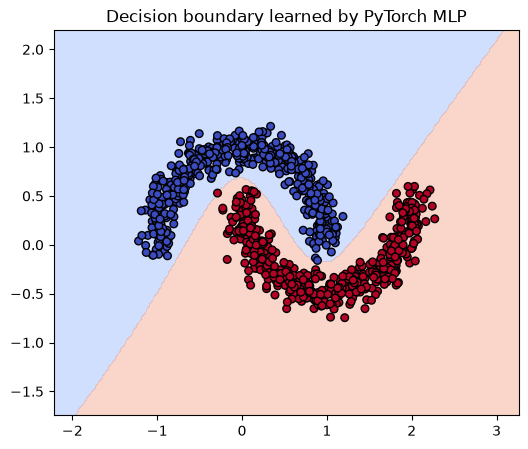

In [26]:
h = 0.02
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)

with torch.no_grad():
    Z = (model(grid) > 0).numpy().reshape(xx.shape)

fig, ax = plt.subplots(figsize=(6, 5))
ax.contourf(xx, yy, Z, cmap='coolwarm', alpha=0.4)
ax.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', s=30, edgecolors='k')
ax.set_title('Decision boundary learned by PyTorch MLP')